# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** M. Khamim Ma'ruf
- **Email:** m.khamimmaruf123@gmail.com
- **ID Dicoding:** khamimmaruf123

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana pengaruh perubahan musim (*season*) dan kondisi cuaca (*weathersit*) terhadap rata-rata penyewaan sepeda harian oleh pengguna *casual* dan *registered* selama periode 2011–2012?
- **Pertanyaan 2:** Bagaimana perbedaan pola jam sibuk (*peak hours*) penyewaan sepeda antara hari kerja (*working day*) dan akhir pekan/hari libur (*weekend/holiday*) berdasarkan data per jam tahun 2011–2012?

## Import Semua Packages/Library yang Digunakan

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

## Data Wrangling



### Gathering Data

#### Load df ...

#### Load Dataset Bike Sharing (`day.csv` dan `hour.csv`)

In [ ]:
day_df = pd.read_csv("day.csv")
hour_df = pd.read_csv("hour.csv")

print("Data Harian (day_df):", day_df.shape)
display(day_df.head())

print("\nData Per Jam (hour_df):", hour_df.shape)
display(hour_df.head())

Data Harian (day_df): (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



Data Per Jam (hour_df): (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Dataset berhasil dimuat ke dalam dua DataFrame utama, yaitu `day_df` (731 baris, 16 kolom) yang merekam penyewaan harian dan `hour_df` (17.379 baris, 17 kolom) yang merekam penyewaan per jam selama tahun 2011–2012.
- Perbedaan utama antara kedua tabel terletak pada kolom `hr` (jam ke-0 hingga ke-23) yang hanya tersedia pada `hour_df`.

### Assessing Data

#### Identifying ... problem
#### Identifying Data Quality Issues (`day_df` dan `hour_df`)

In [ ]:
print("=== INFO DAY_DF ===")
day_df.info()
print("\nMissing values day_df:\n", day_df.isna().sum())
print("Jumlah duplikasi day_df:", day_df.duplicated().sum())
display(day_df.describe())

print("\n=== INFO HOUR_DF ===")
hour_df.info()
print("\nMissing values hour_df:\n", hour_df.isna().sum())
print("Jumlah duplikasi hour_df:", hour_df.duplicated().sum())
display(hour_df.describe())

=== INFO DAY_DF ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Missing values day_df:
 instant       0
dteday        0
season        0


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000



=== INFO HOUR_DF ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB

Missing values hour_df:
 i

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Steps to Take:**
- Mengubah tipe data kolom `dteday` pada `day_df` dan `hour_df` dari `object` menjadi `datetime`.
- Mengonversi nilai numerik pada kolom kategori (`season`, `weathersit`, `workingday`, `yr`, `mnth`) menjadi label teks yang deskriptif agar mudah diinterpretasikan saat eksplorasi dan visualisasi.
- Menyeragamkan nama kolom agar lebih konsisten (misalnya `dteday` menjadi `date`, `cnt` menjadi `total_count`, `weathersit` menjadi `weather_condition`, dan `hr` menjadi `hour`).

**Insight:** (Opsional)
- Tidak ditemukan *missing values* (nilai kosong) maupun baris data duplikat pada `day_df` dan `hour_df`.
- Seluruh nilai statistik minimum dan maksimum pada kolom numerik (`temp`, `hum`, `windspeed`, `casual`, `registered`, `cnt`) berada dalam rentang wajar tanpa kejanggalan data ekstrem yang tidak masuk akal.
- Satu-satunya ketidaksesuaian teknis adalah tipe data `dteday` yang masih terbaca sebagai `object` dan kode kategori yang masih berupa angka integer.

### Cleaning Data

#### Fixing ... problem
#### Fixing Data Types & Mapping Category Labels

In [ ]:
# 1. Mengubah tipe data tanggal menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 2. Mapping label kategori agar deskriptif
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weather_map = {
    1: 'Clear / Partly Cloudy',
    2: 'Mist / Cloudy',
    3: 'Light Snow / Rain',
    4: 'Heavy Rain / Ice'
}
workingday_map = {0: 'Akhir Pekan / Libur', 1: 'Hari Kerja'}

for df in [day_df, hour_df]:
    df['season'] = df['season'].map(season_map)
    df['weather_condition'] = df['weathersit'].map(weather_map)
    df['workingday_label'] = df['workingday'].map(workingday_map)

# 3. Menyeragamkan nama kolom utama
day_df.rename(columns={'dteday': 'date', 'cnt': 'total_count'}, inplace=True)
hour_df.rename(columns={'dteday': 'date', 'hr': 'hour', 'cnt': 'total_count'}, inplace=True)

# 4. Menyimpan dataset bersih untuk kebutuhan dashboard Streamlit
day_df.to_csv("main_day_data.csv", index=False)
hour_df.to_csv("main_hour_data.csv", index=False)

print("Tipe data setelah cleaning:")
print(day_df[['date', 'season', 'weather_condition', 'workingday_label', 'total_count']].dtypes)
display(day_df[['date', 'season', 'weather_condition', 'workingday_label', 'casual', 'registered', 'total_count']].head())

Tipe data setelah cleaning:
date                 datetime64[ns]
season                       object
weather_condition            object
workingday_label             object
total_count                   int64
dtype: object


,date,season,weather_condition,workingday_label,casual,registered,total_count
0,2011-01-01,Spring,Mist / Cloudy,Akhir Pekan / Libur,331,654,985
1,2011-01-02,Spring,Mist / Cloudy,Akhir Pekan / Libur,131,670,801
2,2011-01-03,Spring,Clear / Partly Cloudy,Hari Kerja,120,1229,1349
3,2011-01-04,Spring,Clear / Partly Cloudy,Hari Kerja,108,1454,1562
4,2011-01-05,Spring,Clear / Partly Cloudy,Hari Kerja,82,1518,1600


**Insight:** (Opsional)

- Kolom tanggal (`date`) pada kedua dataset telah berhasil dikonversi ke format `datetime64[ns]`.
- Nilai numerik pada kolom kategori (`season`, `weather_condition`, dan `workingday_label`) sudah dipetakan menjadi label teks yang deskriptif sehingga mudah diinterpretasikan pada tahap eksplorasi maupun visualisasi.
- Nama kolom utama telah diseragamkan (`date`, `hour`, dan `total_count`) dan kedua dataset bersih diekspor menjadi `main_day_data.csv` serta `main_hour_data.csv`.

## Exploratory Data Analysis (EDA)

### Explore ...
### Explore Pola Penyewaan Berdasarkan Musim, Cuaca, dan Jam Operasional

In [ ]:
# 1. Eksplorasi rata-rata penyewaan harian berdasarkan musim (season)
season_eda = day_df.groupby('season', observed=False)[['casual', 'registered', 'total_count']].mean().reindex(['Spring', 'Summer', 'Fall', 'Winter'])
print("=== Rata-rata Penyewaan Harian per Musim ===")
display(season_eda.round(1))

# 2. Eksplorasi rata-rata penyewaan harian berdasarkan kondisi cuaca
weather_eda = day_df.groupby('weather_condition', observed=False)[['casual', 'registered', 'total_count']].mean()
print("\n=== Rata-rata Penyewaan Harian per Kondisi Cuaca ===")
display(weather_eda.round(1))

# 3. Eksplorasi pola penyewaan per jam pada hari kerja vs akhir pekan/libur
hourly_eda = hour_df.groupby(['workingday_label', 'hour'], observed=False)['total_count'].mean().unstack(level=0)
print("\n=== Rata-rata Penyewaan per Jam (Top 5 Jam Tertinggi Hari Kerja) ===")
display(hourly_eda.sort_values(by='Hari Kerja', ascending=False).head(5).round(1))

print("\n=== Rata-rata Penyewaan per Jam (Top 5 Jam Tertinggi Akhir Pekan / Libur) ===")
display(hourly_eda.sort_values(by='Akhir Pekan / Libur', ascending=False).head(5).round(1))

=== Rata-rata Penyewaan Harian per Musim ===


,casual,registered,total_count
season,,,
Spring,334.9,2269.2,2604.1
Summer,1106.1,3886.2,4992.3
Fall,1202.6,4441.7,5644.3
Winter,729.1,3999.1,4728.2



=== Rata-rata Penyewaan Harian per Kondisi Cuaca ===


,casual,registered,total_count
weather_condition,,,
Clear / Partly Cloudy,964.0,3912.8,4876.8
Light Snow / Rain,185.5,1617.8,1803.3
Mist / Cloudy,687.4,3348.5,4035.9



=== Rata-rata Penyewaan per Jam (Top 5 Jam Tertinggi Hari Kerja) ===


workingday_label,Akhir Pekan / Libur,Hari Kerja
hour,,
17,323.5,525.3
18,281.1,492.2
8,105.7,477.0
19,231.7,348.4
16,352.7,293.1



=== Rata-rata Penyewaan per Jam (Top 5 Jam Tertinggi Akhir Pekan / Libur) ===


workingday_label,Akhir Pekan / Libur,Hari Kerja
hour,,
13,372.7,198.4
12,366.3,200.8
14,364.6,183.6
15,358.8,201.3
16,352.7,293.1


**Insight:** (Opsional)

- **Berdasarkan Musim:** Musim gugur (*Fall*) mencatat rata-rata penyewaan harian tertinggi (5.644,3 penyewaan/hari), diikuti *Summer* (4.992,3), *Winter* (4.728,2), dan terendah pada *Spring* (2.604,1).
- **Berdasarkan Cuaca:** Kondisi cuaca cerah/berawan sebagian (*Clear / Partly Cloudy*) menghasilkan rata-rata penyewaan tertinggi (4.876,8/hari), sedangkan cuaca hujan ringan/salju (*Light Snow / Rain*) menurunkan penyewaan secara drastis lebih dari 60% (menjadi 1.803,3/hari).
- **Berdasarkan Jam & Tipe Hari:** Pada hari kerja, puncak penyewaan terjadi pada jam berangkat kerja (pukul 08:00) dan pulang kerja (pukul 17:00–18:00). Sebaliknya, pada akhir pekan/libur, puncak penyewaan bergeser ke siang hingga sore hari (pukul 12:00–16:00).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana pengaruh perubahan musim (*season*) dan kondisi cuaca (*weathersit*) terhadap rata-rata penyewaan sepeda harian oleh pengguna *casual* dan *registered* selama periode 2011–2012?

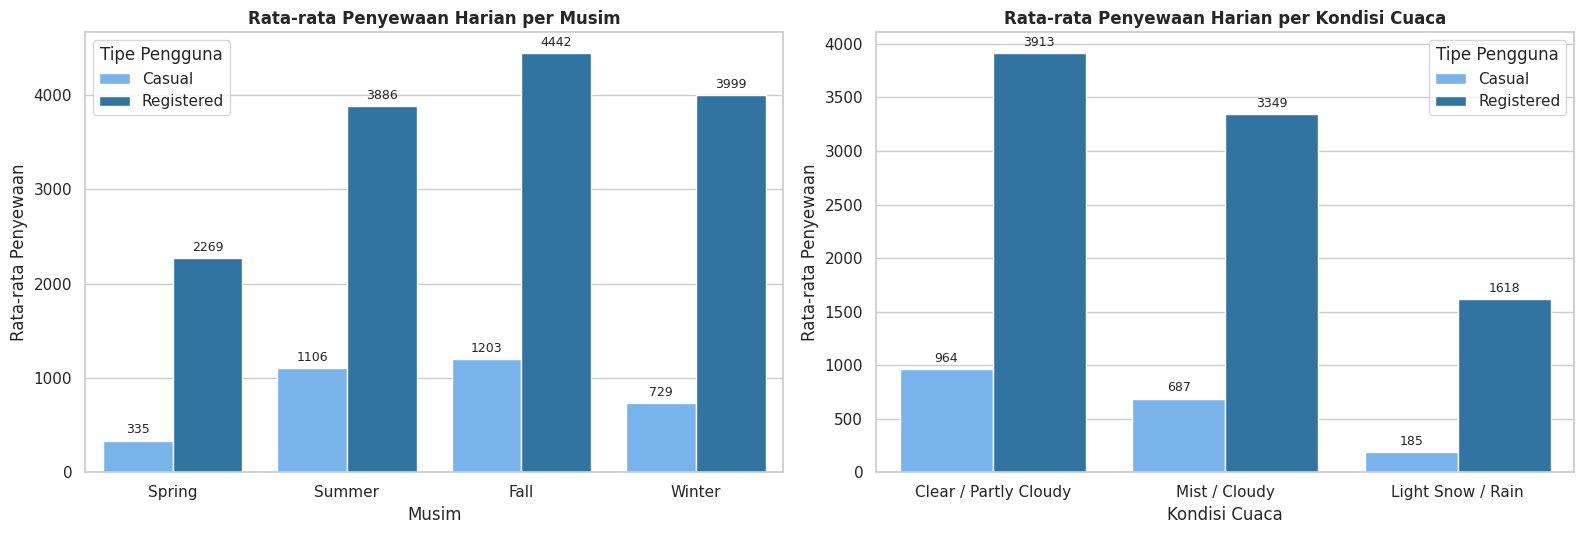

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Grafik 1: Pengaruh Musim
season_order = ['Spring', 'Summer', 'Fall', 'Winter']
season_melt = day_df.melt(
    id_vars='season',
    value_vars=['casual', 'registered'],
    var_name='user_type',
    value_name='avg_rentals'
)
sns.barplot(
    data=season_melt,
    x='season',
    y='avg_rentals',
    hue='user_type',
    order=season_order,
    palette=['#66b3ff', '#1f77b4'],
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title("Rata-rata Penyewaan Harian per Musim", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Musim")
axes[0].set_ylabel("Rata-rata Penyewaan")
axes[0].legend(title="Tipe Pengguna", labels=["Casual", "Registered"])
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.0f', padding=3, fontsize=9)

# Grafik 2: Pengaruh Kondisi Cuaca
weather_order = ['Clear / Partly Cloudy', 'Mist / Cloudy', 'Light Snow / Rain']
weather_melt = day_df.melt(
    id_vars='weather_condition',
    value_vars=['casual', 'registered'],
    var_name='user_type',
    value_name='avg_rentals'
)
sns.barplot(
    data=weather_melt,
    x='weather_condition',
    y='avg_rentals',
    hue='user_type',
    order=weather_order,
    palette=['#66b3ff', '#1f77b4'],
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title("Rata-rata Penyewaan Harian per Kondisi Cuaca", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Kondisi Cuaca")
axes[1].set_ylabel("Rata-rata Penyewaan")
axes[1].legend(title="Tipe Pengguna", labels=["Casual", "Registered"])
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.0f', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana perbedaan pola jam sibuk (*peak hours*) penyewaan sepeda antara hari kerja (*working day*) dan akhir pekan/hari libur (*weekend/holiday*) berdasarkan data per jam tahun 2011–2012?

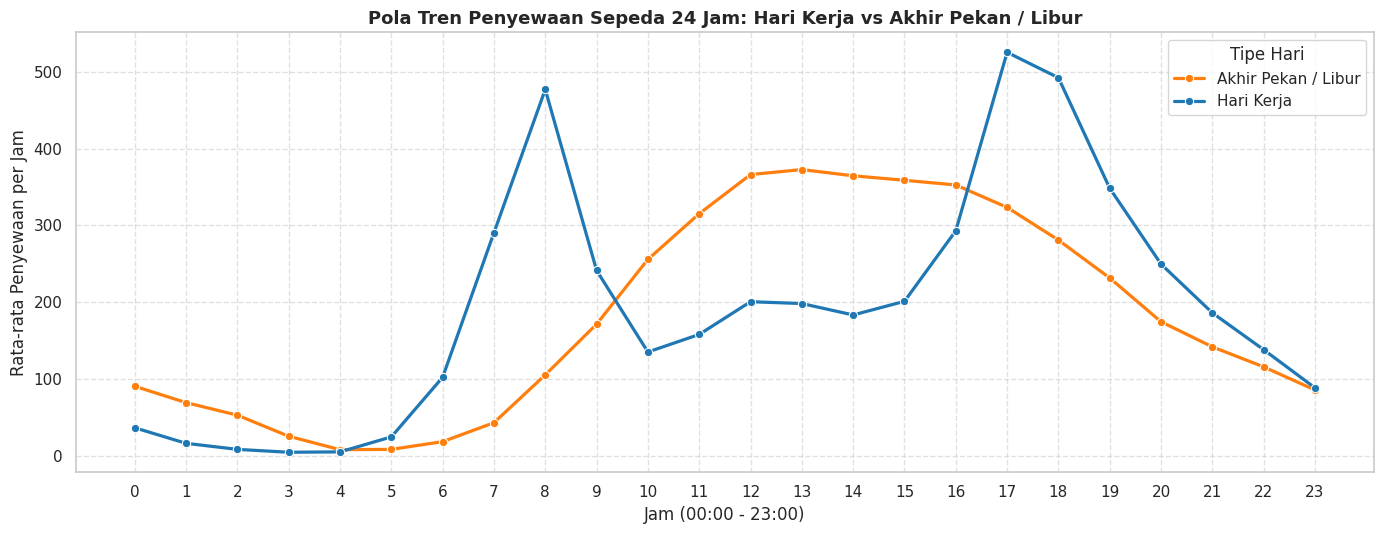

In [ ]:
plt.figure(figsize=(14, 5.5))

sns.lineplot(
    data=hour_df,
    x='hour',
    y='total_count',
    hue='workingday_label',
    palette=['#ff7f0e', '#1f77b4'],
    marker='o',
    linewidth=2.3,
    errorbar=None
)

plt.title("Pola Tren Penyewaan Sepeda 24 Jam: Hari Kerja vs Akhir Pekan / Libur", fontsize=13, fontweight='bold')
plt.xlabel("Jam (00:00 - 23:00)")
plt.ylabel("Rata-rata Penyewaan per Jam")
plt.xticks(range(0, 24))
plt.legend(title="Tipe Hari")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)

- **Dominasi Pengguna Registered & Sensitivitas Cuaca:** Pengguna *registered* menyumbang porsi penyewaan jauh lebih besar di semua musim dan kondisi cuaca. Namun, pengguna *casual* jauh lebih sensitif terhadap cuaca buruk dan suhu dingin (*Winter* / *Spring*).
- **Pola Bimodal vs Unimodal:** Grafik garis 24 jam memperlihatkan pola dua puncak tajam (*bimodal*) pada hari kerja (pukul 08:00 dan 17:00) yang mencerminkan aktivitas komuter pekerja/pelajar, sedangkan akhir pekan membentuk satu kurva landai (*unimodal*) yang ramai sepanjang pukul 11:00–17:00.

## Analisis Lanjutan (Opsional)

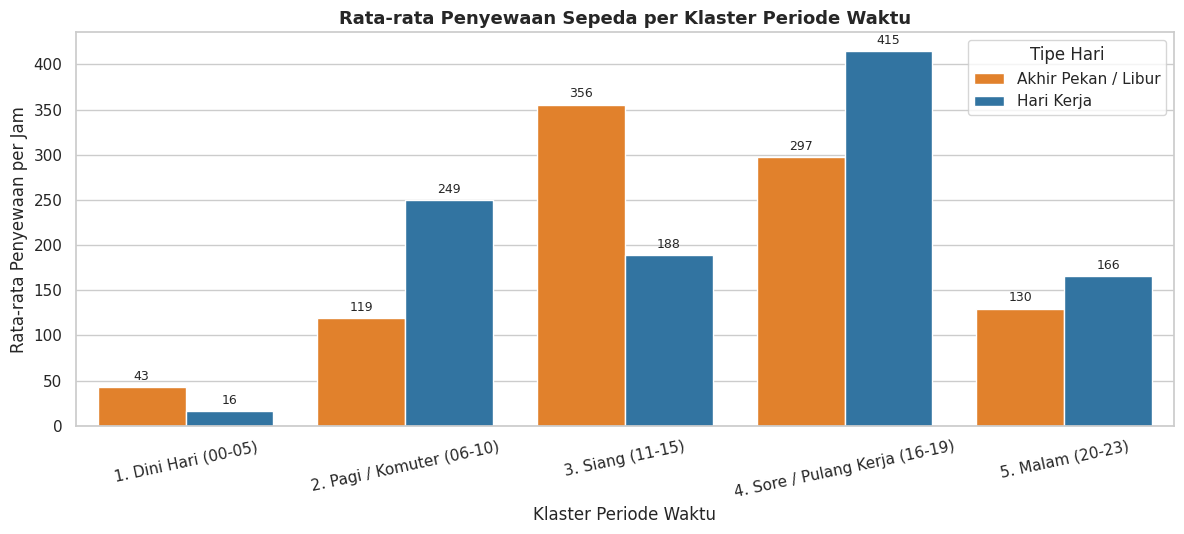

In [ ]:
# Teknik Analisis Lanjutan: Manual Grouping / Clustering berdasarkan Periode Waktu Operasional
def categorize_time_period(hr):
    if 0 <= hr <= 5:
        return '1. Dini Hari (00-05)'
    elif 6 <= hr <= 10:
        return '2. Pagi / Komuter (06-10)'
    elif 11 <= hr <= 15:
        return '3. Siang (11-15)'
    elif 16 <= hr <= 19:
        return '4. Sore / Pulang Kerja (16-19)'
    else:
        return '5. Malam (20-23)'

hour_df['time_period'] = hour_df['hour'].apply(categorize_time_period)

# Simpan ulang main_hour_data.csv agar kolom time_period ikut tersimpan
hour_df.to_csv("main_hour_data.csv", index=False)

period_order = [
    '1. Dini Hari (00-05)',
    '2. Pagi / Komuter (06-10)',
    '3. Siang (11-15)',
    '4. Sore / Pulang Kerja (16-19)',
    '5. Malam (20-23)'
]

plt.figure(figsize=(12, 5.5))
ax = sns.barplot(
    data=hour_df,
    x='time_period',
    y='total_count',
    hue='workingday_label',
    order=period_order,
    palette=['#ff7f0e', '#1f77b4'],
    errorbar=None
)
plt.title("Rata-rata Penyewaan Sepeda per Klaster Periode Waktu", fontsize=13, fontweight='bold')
plt.xlabel("Klaster Periode Waktu")
plt.ylabel("Rata-rata Penyewaan per Jam")
plt.xticks(rotation=12)
plt.legend(title="Tipe Hari")
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

**Insight:** (Opsional)

- Klaster **4. Sore / Pulang Kerja (16-19)** merupakan periode dengan rata-rata permintaan tertinggi sepanjang hari, khususnya pada **Hari Kerja** yang mencapai **415** penyewaan/jam (dan **297** penyewaan/jam pada **Akhir Pekan / Libur**).
- Pada **Akhir Pekan / Libur**, beban permintaan tertinggi justru terpusat pada klaster **3. Siang (11-15)** sebesar **356** penyewaan/jam, sedangkan klaster **1. Dini Hari (00-05)** mencatat permintaan paling rendah di semua tipe hari (**43** pada akhir pekan/libur dan **16** pada hari kerja)[cite: 9].

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Musim dan kondisi cuaca berpengaruh signifikan terhadap volume penyewaan sepeda. Musim gugur (*Fall*) mencatat rata-rata penyewaan tertinggi (5.644 sepeda/hari), sedangkan musim semi (*Spring*) terendah (2.604 sepeda/hari). Cuaca cerah (*Clear/Partly Cloudy*) menghasilkan penyewaan hampir 2,7 kali lipat lebih tinggi dibandingkan saat hujan ringan/salju. Pengguna *registered* merupakan tulang punggung penyewaan yang relatif stabil di berbagai musim, sementara pengguna *casual* sangat bergantung pada cuaca cerah dan musim hangat (*Summer* & *Fall*).
- **Conclusion pertanyaan 2:** Terdapat perbedaan pola jam sibuk yang kontras antara hari kerja dan akhir pekan. Hari kerja memiliki dua puncak komuter tajam pada pukul **08:00** (~477 penyewaan/jam) dan pukul **17:00–18:00** (~525 penyewaan/jam). Sebaliknya, akhir pekan/hari libur memiliki pola rekreasi dengan satu puncak lebar pada siang hingga sore hari (**12:00–16:00**, rata-rata >350 penyewaan/jam).

**Rekomendasi Action Item:**
- **Penjadwalan Distribusi Armada Berbasis Waktu:** Pada hari kerja, lakukan pengisian ulang (*rebalancing*) stok sepeda di stasiun dekat area perumahan/transportasi umum sebelum pukul **07:00**, serta di area perkantoran/kampus sebelum pukul **16:00**. Pada akhir pekan, fokuskan ketersediaan armada di titik wisata dan taman kota mulai pukul **10:30 hingga 17:00**.
- **Jadwal Perawatan (Maintenance) Armada:** Manfaatkan klaster **Dini Hari (00:00–05:00)** serta periode musim dengan permintaan rendah (**Spring** dan **Winter**) untuk melakukan perawatan besar atau perbaikan unit sepeda agar tidak mengganggu ketersediaan armada saat puncak permintaan.
- **Strategi Promosi Segmen Casual:** Tawarkan promo paket *weekend pass* atau diskon cuaca cerah khusus pengguna *casual* pada musim *Summer* dan *Fall* untuk mendorong konversi mereka menjadi anggota *registered*.